# Lab 1 - Nhan dien cam xuc khuon mat
## Train notebook (chay tren Kaggle GPU)

**Dataset:** FER-2013 (`msambare/fer2013`)
**Models:** M1 - Custom CNN | M2 - EfficientNet-B0 + CBAM Attention
**Ky thuat nang cao:** Gradual Unfreezing, Label Smoothing (0.1), Early Stopping, Class Weights
**Muc tieu:** M1 >= 60% | M2 >= 70-75% accuracy tren tap test


## 0. Setup & Imports

In [1]:
import os, time, copy
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

import torchvision.models as models
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, f1_score, classification_report
)

BATCH_SIZE = 64
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")
print(f"PyTorch version: {torch.__version__}")

Device: cuda
PyTorch version: 2.10.0+cu128


## 0.5. Khám phá cấu trúc thư mục dataset
> Chạy cell này TRƯỚC để xác nhận đường dẫn đúng


In [2]:
# == Đường dẫn dataset trên Kaggle ==
BASE_INPUT = "/kaggle/input/datasets/msambare/fer2013"
TRAIN_DIR = os.path.join(BASE_INPUT, "train")
TEST_DIR = os.path.join(BASE_INPUT, "test")

# == Danh sách lớp mặc định (dùng để so sánh/auto-update bên dưới) ==
CLASSES = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]
CLASS_NAMES = [c.capitalize() for c in CLASSES]
NUM_CLASSES = len(CLASSES)


# == Kiem tra cau truc thu muc dataset ==
# Dataset dung la msambare/fer2013 (Add Data > Datasets, khong phai Notebooks)
# Neu chua add: Kaggle notebook -> + Add Data -> Datasets -> tim "fer2013" -> chon msambare/fer2013

def explore_dir(path, depth=0, max_depth=2):
    """In cay thu muc."""
    if depth > max_depth or not os.path.exists(path):
        return
    items = sorted(os.listdir(path))
    for item in items[:10]:
        full = os.path.join(path, item)
        if os.path.isdir(full):
            n = len(os.listdir(full))
            print("  " * depth + f"[DIR ] {item}/ ({n} items)")
            explore_dir(full, depth + 1, max_depth)
        else:
            sz = os.path.getsize(full) // 1024
            print("  " * depth + f"[FILE] {item} ({sz}KB)")
    if len(items) > 10:
        print("  " * depth + f"... va {len(items)-10} items khac")

print(f"=== Cau truc: {BASE_INPUT} ===")
if os.path.exists(BASE_INPUT):
    explore_dir(BASE_INPUT, max_depth=2)
else:
    print(f"[ERROR] Khong ton tai: {BASE_INPUT}")
    print("Huong dan:")
    print("  1. Trong Kaggle notebook, click [ + Add Data ] (goc tren phai)")
    print("  2. Chon tab [Datasets] (KHONG phai Notebooks)")
    print("  3. Tim: fer2013")
    print("  4. Chon: msambare / fer2013")
    print("  5. Click Add -> Re-run notebook")

# Kiem tra TRAIN_DIR/TEST_DIR
print(f"\nTRAIN_DIR exists: {os.path.exists(TRAIN_DIR)}")
print(f"TEST_DIR  exists: {os.path.exists(TEST_DIR)}")

if os.path.exists(TRAIN_DIR):
    subdirs = sorted(os.listdir(TRAIN_DIR))
    counts  = [len(os.listdir(os.path.join(TRAIN_DIR, d))) for d in subdirs]
    print(f"\nClasses trong train/:")
    for cls, cnt in zip(subdirs, counts):
        print(f"  {cls:<12} {cnt:>5} anh")
    print(f"  TOTAL        {sum(counts):>5} anh")
    # Auto update CLASSES neu ten lop khac
    if set(subdirs) != set(CLASSES):
        print(f"[WARN] Ten lop khac mac dinh! Cap nhat tu dong...")
        CLASSES = subdirs
        CLASS_NAMES = [c.capitalize() for c in CLASSES]
        NUM_CLASSES = len(CLASSES)
        print(f"[OK]  CLASSES = {CLASSES}")
    else:
        print("[OK] Ten lop khop voi mac dinh")
else:
    raise RuntimeError(
        f"TRAIN_DIR khong ton tai: {TRAIN_DIR}\n"
        "Hay add dataset msambare/fer2013 qua Add Data > Datasets"
    )

=== Cau truc: /kaggle/input/datasets/msambare/fer2013 ===
[DIR ] test/ (7 items)
  [DIR ] angry/ (958 items)
    [FILE] PrivateTest_10131363.jpg (1KB)
    [FILE] PrivateTest_10304478.jpg (1KB)
    [FILE] PrivateTest_1054527.jpg (1KB)
    [FILE] PrivateTest_10590091.jpg (1KB)
    [FILE] PrivateTest_1109992.jpg (1KB)
    [FILE] PrivateTest_11296953.jpg (1KB)
    [FILE] PrivateTest_12000629.jpg (1KB)
    [FILE] PrivateTest_12008383.jpg (1KB)
    [FILE] PrivateTest_12191716.jpg (1KB)
    [FILE] PrivateTest_1221822.jpg (1KB)
    ... va 948 items khac
  [DIR ] disgust/ (111 items)
    [FILE] PrivateTest_11895083.jpg (1KB)
    [FILE] PrivateTest_19671520.jpg (1KB)
    [FILE] PrivateTest_21629266.jpg (1KB)
    [FILE] PrivateTest_22382996.jpg (1KB)
    [FILE] PrivateTest_26306320.jpg (1KB)
    [FILE] PrivateTest_29901781.jpg (1KB)
    [FILE] PrivateTest_30523217.jpg (1KB)
    [FILE] PrivateTest_34013087.jpg (1KB)
    [FILE] PrivateTest_34426922.jpg (1KB)
    [FILE] PrivateTest_36627671.jpg (1KB

## 1. EDA – Phân tích dữ liệu

=== Phân bố lớp ===
     Class     Train      Test
     angry      3995       958
   disgust       436       111
      fear      4097      1024
     happy      7215      1774
   neutral      4965      1233
       sad      4830      1247
  surprise      3171       831
     TOTAL     28709      7178


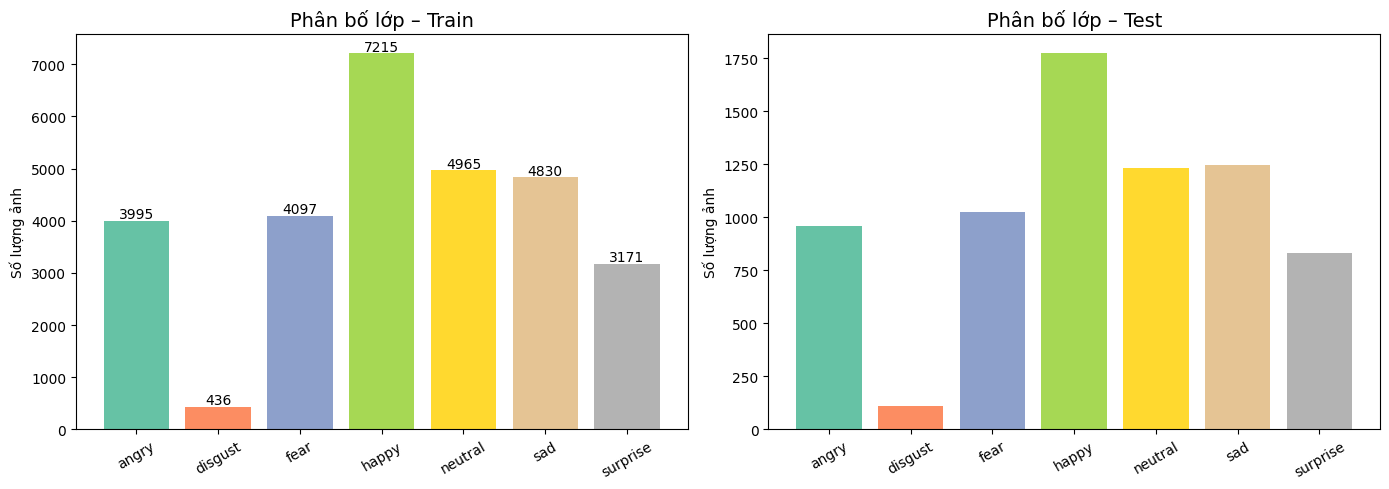

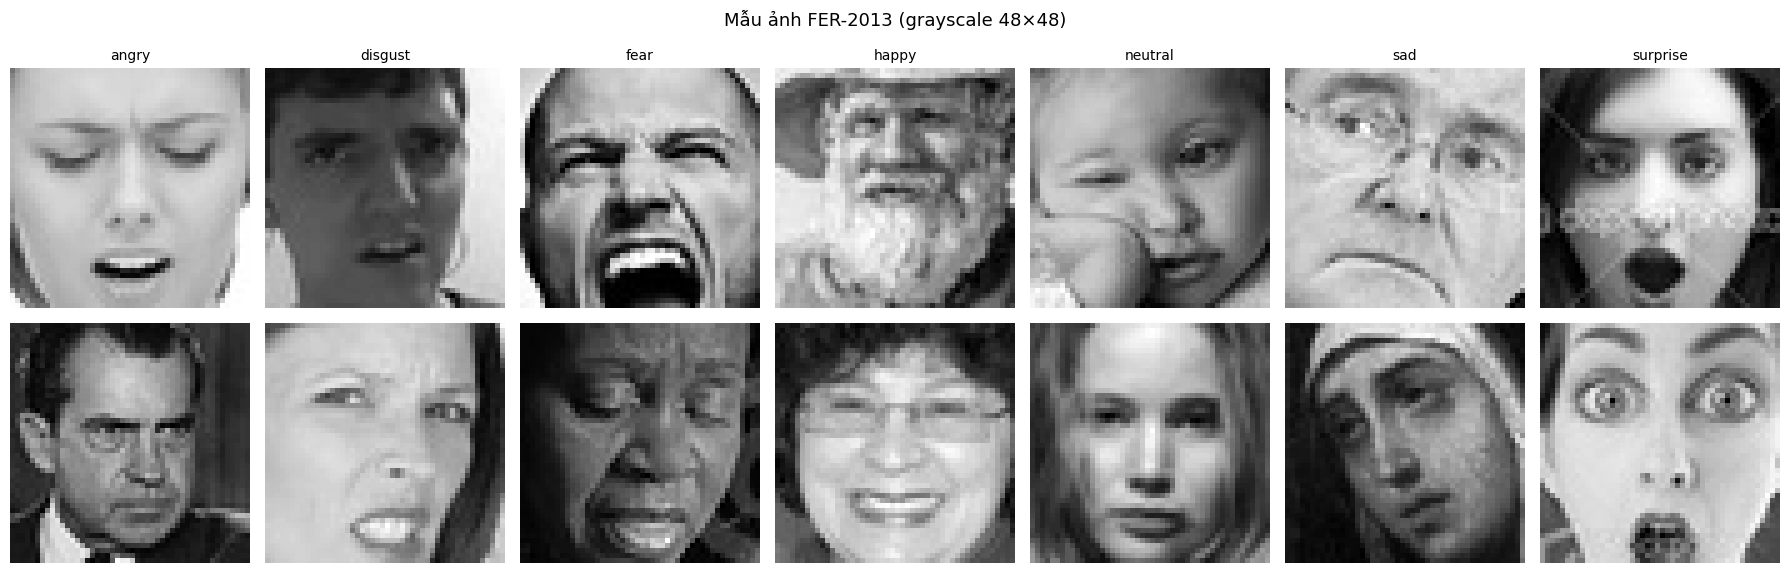

In [3]:
# ── 1.1 Thống kê số lượng ảnh mỗi lớp ──────────────────────────────────
train_counts = [len(os.listdir(os.path.join(TRAIN_DIR, c))) for c in CLASSES]
test_counts  = [len(os.listdir(os.path.join(TEST_DIR,  c))) for c in CLASSES]

print('=== Phân bố lớp ===')
print(f'{"Class":>10}  {"Train":>8}  {"Test":>8}')
for cls, tr, te in zip(CLASSES, train_counts, test_counts):
    print(f'{cls:>10}  {tr:>8}  {te:>8}')
print(f'{"TOTAL":>10}  {sum(train_counts):>8}  {sum(test_counts):>8}')

# ── 1.2 Biểu đồ phân bố ─────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = plt.cm.Set2(np.linspace(0, 1, NUM_CLASSES))
axes[0].bar(CLASSES, train_counts, color=colors)
axes[0].set_title('Phân bố lớp – Train', fontsize=14)
axes[0].set_ylabel('Số lượng ảnh')
axes[0].tick_params(axis='x', rotation=30)
for i, v in enumerate(train_counts):
    axes[0].text(i, v + 50, str(v), ha='center', fontsize=10)

axes[1].bar(CLASSES, test_counts, color=colors)
axes[1].set_title('Phân bố lớp – Test', fontsize=14)
axes[1].set_ylabel('Số lượng ảnh')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150)
plt.show()

# ── 1.3 Xem mẫu ảnh ─────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 7, figsize=(18, 6))
for col, cls in enumerate(CLASSES):
    cls_dir = os.path.join(TRAIN_DIR, cls)
    imgs = os.listdir(cls_dir)
    for row in range(2):
        img_path = os.path.join(cls_dir, imgs[row])
        from PIL import Image
        img = np.array(Image.open(img_path).convert('L'))
        axes[row][col].imshow(img, cmap='gray')
        axes[row][col].set_title(cls if row == 0 else '', fontsize=10)
        axes[row][col].axis('off')
plt.suptitle('Mẫu ảnh FER-2013 (grayscale 48×48)', fontsize=13)
plt.tight_layout()
plt.savefig('sample_images.png', dpi=150)
plt.show()

## 2. Chuẩn bị dữ liệu – Transforms & DataLoaders

In [4]:
# ── Class weights ────────────────────────────────────────────────────────
all_labels = []
for i, cls in enumerate(CLASSES):
    all_labels.extend([i] * train_counts[i])

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(NUM_CLASSES),
    y=all_labels
)
class_weights = np.sqrt(class_weights) 
print('Class weights:', np.round(class_weights, 3))

# ── Transforms ──────────────────────────────────────────────────────────
# M1 – CNN: grayscale 48×48
CNN_TRAIN_TRANSFORM = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((48, 48)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5]),
    transforms.RandomErasing(p=0.3, scale=(0.02, 0.1)),
])

CNN_TEST_TRANSFORM = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((48, 48)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5]),
])

# M2 – MobileNetV2: 3-channel 224×224
MOB_TRAIN_TRANSFORM = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

MOB_TEST_TRANSFORM = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

# ── DataLoaders ──────────────────────────────────────────────────────────
def make_loaders(train_tf, test_tf, batch_size=BATCH_SIZE):
    train_ds = ImageFolder(TRAIN_DIR, transform=train_tf)
    test_ds  = ImageFolder(TEST_DIR,  transform=test_tf)
    train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True,  num_workers=2, pin_memory=True)
    test_dl  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
    return train_dl, test_dl

cnn_train_loader, cnn_test_loader = make_loaders(CNN_TRAIN_TRANSFORM, CNN_TEST_TRANSFORM)
mob_train_loader, mob_test_loader = make_loaders(MOB_TRAIN_TRANSFORM, MOB_TEST_TRANSFORM)

print(f'CNN  – Train batches: {len(cnn_train_loader)} | Test batches: {len(cnn_test_loader)}')
print(f'MNet – Train batches: {len(mob_train_loader)} | Test batches: {len(mob_test_loader)}')
x, y = next(iter(cnn_train_loader))
print(f'CNN  – Batch shape: {x.shape}, labels: {y[:8].tolist()}')

Class weights: [1.013 3.067 1.001 0.754 0.909 0.921 1.137]
CNN  – Train batches: 449 | Test batches: 113
MNet – Train batches: 449 | Test batches: 113
CNN  – Batch shape: torch.Size([64, 1, 48, 48]), labels: [3, 2, 0, 0, 6, 5, 6, 5]


## 3. Định nghĩa Model

In [5]:

# M1: EmotionCNN  (copy sang src/model.py trn local)
class EmotionCNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.features = nn.Sequential(
            # Block 1: 
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2), nn.Dropout2d(0.1),
            # Block 2: 
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2), nn.Dropout2d(0.1),
            # Block 3: 
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2), nn.Dropout2d(0.1),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 6 * 6, 256), nn.ReLU(inplace=True), nn.Dropout(0.5),
            nn.Linear(256, num_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))


# CBAM (Channel & Spatial Attention Module)

class ChannelAttention(nn.Module):
    def __init__(self, in_planes, ratio=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.fc = nn.Sequential(
            nn.Conv2d(in_planes, max(1, in_planes // ratio), 1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(max(1, in_planes // ratio), in_planes, 1, bias=False)
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = self.fc(self.avg_pool(x))
        max_out = self.fc(self.max_pool(x))
        return self.sigmoid(avg_out + max_out)

class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size=kernel_size, padding=kernel_size // 2, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        x_cat = torch.cat([avg_out, max_out], dim=1)
        return self.sigmoid(self.conv(x_cat))

class CBAM(nn.Module):
    def __init__(self, in_planes, ratio=16, kernel_size=7):
        super().__init__()
        self.ca = ChannelAttention(in_planes, ratio)
        self.sa = SpatialAttention(kernel_size)

    def forward(self, x):
        x = x * self.ca(x)
        x = x * self.sa(x)
        return x

# M2: EmotionEfficientNetCBAM (EfficientNet-B0 + CBAM Attention)
class EmotionEfficientNetCBAM(nn.Module):
    def __init__(self, num_classes=7, pretrained=True):
        super().__init__()
        weights = models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
        self.backbone = models.efficientnet_b0(weights=weights)
        in_features = self.backbone.classifier[1].in_features  # 1280
        self.cbam = CBAM(in_planes=in_features)
        self.backbone.classifier = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(in_features, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x = self.backbone.features(x)
        x = self.cbam(x)
        x = self.backbone.avgpool(x)
        x = torch.flatten(x, 1)
        return self.backbone.classifier(x)

    def freeze_backbone(self):
        for param in self.backbone.features.parameters():
            param.requires_grad = False
        self.backbone.features.eval()

    def unfreeze_stage(self, stage_idx=6):
        for param in self.backbone.features[stage_idx:].parameters():
            param.requires_grad = True

    def unfreeze_all(self):
        for param in self.backbone.parameters():
            param.requires_grad = True

# Alias tuong thich cho cac cell sau
EmotionMobileNet = EmotionEfficientNetCBAM

# Kiem tra
cnn = EmotionCNN(); mob = EmotionEfficientNetCBAM(pretrained=False)
print(f'EmotionCNN              params: {sum(p.numel() for p in cnn.parameters()):,}')
print(f'EmotionEfficientNetCBAM params: {sum(p.numel() for p in mob.parameters()):,}')


EmotionCNN              params: 1,321,191
EmotionEfficientNetCBAM params: 4,542,693


## 4a. Train M1 – Custom CNN

In [6]:
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.0005, mode='max'):
        self.patience = patience
        self.min_delta = min_delta
        self.mode = mode
        self.counter = 0
        self.best_score = None
        self.early_stop = False

    def __call__(self, val_metric):
        score = val_metric if self.mode == 'max' else -val_metric
        if self.best_score is None:
            self.best_score = score
        elif score < self.best_score + self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.counter = 0
            self.early_stop = False


def mixup_data(x, y, alpha=0.2):
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1.0
    index = torch.randperm(x.size(0), device=x.device)
    mixed_x = lam * x + (1 - lam) * x[index]
    return mixed_x, y, y[index], lam



def train_one_epoch(model, loader, criterion, optimizer, device, use_mixup=False, mixup_alpha=0.2, use_hnm=False, hnm_ratio=0.7):
    model.train()
    
    bb = getattr(model, 'backbone', None)
    if bb is not None and not any(p.requires_grad for p in bb.features.parameters()):
        bb.features.eval()
      

    total_loss, correct, total = 0., 0., 0
    crit_none = nn.CrossEntropyLoss(weight=criterion.weight,
                                    label_smoothing=criterion.label_smoothing,
                                    reduction='none')
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()

        if use_mixup:
            imgs, y_a, y_b, lam = mixup_data(imgs, labels, alpha=mixup_alpha)
        else:
            y_a, y_b, lam = labels, labels, 1.0

        out = model(imgs)
        per_sample = lam * crit_none(out, y_a) + (1 - lam) * crit_none(out, y_b)

        if use_hnm:
            k = max(1, int(hnm_ratio * per_sample.size(0)))
            loss = per_sample.topk(k).values.mean()
        else:
            loss = per_sample.mean()

        loss.backward()
        optimizer.step()

        bs = imgs.size(0)
        total_loss += per_sample.mean().item() * bs      # log loss toàn batch
        pred = out.argmax(1)
        correct += (lam * (pred == y_a).float()
                    + (1 - lam) * (pred == y_b).float()).sum().item()
        total += bs
    return total_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0., 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        out = model(imgs)
        loss = criterion(out, labels)
        total_loss += loss.item() * imgs.size(0)
        correct    += (out.argmax(1) == labels).sum().item()
        total      += imgs.size(0)
    return total_loss / total, correct / total

def train_model(model, train_loader, test_loader, num_epochs,
                optimizer, criterion, scheduler=None, device=DEVICE, label='', patience=None,
                use_mixup=False, mixup_alpha=0.2, 
                use_hnm=False, hnm_ratio=0.7, hnm_warmup=3):
    model = model.to(device)
    best_acc, best_wts = 0.0, copy.deepcopy(model.state_dict())
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    early_stopping = EarlyStopping(patience=patience) if patience is not None else None

    for epoch in range(1, num_epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device,
                                           use_mixup=use_mixup, mixup_alpha=mixup_alpha, 
                                           use_hnm=(use_hnm and epoch > hnm_warmup),
                                           hnm_ratio=hnm_ratio)
        va_loss, va_acc = evaluate(model, test_loader, criterion, device)

        if scheduler:
            if isinstance(scheduler, optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(va_loss)
            else:
                scheduler.step()

        history['train_loss'].append(tr_loss)
        history['val_loss'].append(va_loss)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(va_acc)

        if va_acc > best_acc:
            best_acc = va_acc
            best_wts = copy.deepcopy(model.state_dict())

        print(f'[{label}] Epoch {epoch:>3}/{num_epochs} | '
              f'Loss {tr_loss:.4f}/{va_loss:.4f} | '
              f'Acc {tr_acc:.4f}/{va_acc:.4f} | '
              f'{time.time()-t0:.1f}s')

        if early_stopping:
            early_stopping(va_acc)
            if early_stopping.early_stop:
                print(f' Early stopping kich hoat tai epoch {epoch} (patience={patience})')
                break

    model.load_state_dict(best_wts)
    print(f'\nBest val accuracy: {best_acc:.4f} ({best_acc*100:.2f}%)')
    return model, history


In [7]:
#  Train M1 
weights_tensor = torch.FloatTensor(class_weights).to(DEVICE)
# Bo sung Label Smoothing (0.1) xu ly noisy labels
criterion = nn.CrossEntropyLoss(weight=weights_tensor, label_smoothing=0.1)

model_cnn = EmotionCNN(num_classes=NUM_CLASSES)
optimizer_cnn = optim.Adam(model_cnn.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler_cnn = optim.lr_scheduler.ReduceLROnPlateau(optimizer_cnn, patience=5, factor=0.5)

model_cnn, history_cnn = train_model(
    model_cnn, cnn_train_loader, cnn_test_loader,
    num_epochs=60, optimizer=optimizer_cnn,
    criterion=criterion, scheduler=scheduler_cnn, label='CNN', patience=10
)

# Luu weights
torch.save(model_cnn.state_dict(), 'model_cnn.pt')
print(' Saved: model_cnn.pt')


[CNN] Epoch   1/60 | Loss 1.9236/1.9422 | Acc 0.2051/0.2857 | 122.2s
[CNN] Epoch   2/60 | Loss 1.8709/1.8641 | Acc 0.2495/0.3681 | 31.8s
[CNN] Epoch   3/60 | Loss 1.8283/1.7847 | Acc 0.2826/0.3905 | 30.7s
[CNN] Epoch   4/60 | Loss 1.8131/1.7762 | Acc 0.2877/0.4166 | 31.5s
[CNN] Epoch   5/60 | Loss 1.8003/1.7725 | Acc 0.3014/0.4157 | 29.0s
[CNN] Epoch   6/60 | Loss 1.7919/1.7178 | Acc 0.3100/0.4334 | 28.9s
[CNN] Epoch   7/60 | Loss 1.7870/1.7036 | Acc 0.3127/0.4266 | 32.0s
[CNN] Epoch   8/60 | Loss 1.7765/1.7061 | Acc 0.3175/0.4459 | 30.2s
[CNN] Epoch   9/60 | Loss 1.7737/1.7215 | Acc 0.3203/0.4411 | 29.2s
[CNN] Epoch  10/60 | Loss 1.7566/1.6419 | Acc 0.3209/0.4451 | 34.3s
[CNN] Epoch  11/60 | Loss 1.7297/1.6376 | Acc 0.3296/0.4529 | 32.6s
[CNN] Epoch  12/60 | Loss 1.7049/1.6323 | Acc 0.3613/0.4444 | 34.8s
[CNN] Epoch  13/60 | Loss 1.6829/1.5818 | Acc 0.3884/0.4721 | 41.9s
[CNN] Epoch  14/60 | Loss 1.6323/1.5870 | Acc 0.4369/0.4923 | 38.4s
[CNN] Epoch  15/60 | Loss 1.5835/1.4938 | Acc 0

## 4b. Train M2  EfficientNet-B0 + CBAM Attention (Gradual Unfreezing, Label Smoothing & Early Stopping)


In [8]:
#  M2 Training Pipeline: EfficientNet-B0 + CBAM Attention 
model_mob = EmotionEfficientNetCBAM(num_classes=NUM_CLASSES, pretrained=True).to(DEVICE)

# === Phase 1: train Classifier Head (Backbone Frozen - Max 10 epochs) ===
model_mob.freeze_backbone()
optimizer_mob_p1 = optim.Adam(
    filter(lambda p: p.requires_grad, model_mob.parameters()),
    lr=1e-3, weight_decay=1e-4
)
scheduler_mob_p1 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_mob_p1, patience=2, factor=0.5)

print('=== Phase 1: train Classifier Head (Backbone Frozen) ===')
model_mob, history_mob_p1 = train_model(
    model_mob, mob_train_loader, mob_test_loader,
    num_epochs=10, optimizer=optimizer_mob_p1,
    criterion=criterion, scheduler=scheduler_mob_p1, label='EffNetCBAM-P1',
    patience=4
)

# === Phase 2: Gradual Unfreeze - Stage 1 (Unfreeze top blocks 6->8) ===
model_mob.unfreeze_stage(6)
optimizer_mob_p2 = optim.Adam(
    filter(lambda p: p.requires_grad, model_mob.parameters()),
    lr=1e-4, weight_decay=1e-4
)
scheduler_mob_p2 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_mob_p2, patience=2, factor=0.5)

print('\n=== Phase 2: Gradual Unfreeze - Stage 1 (Top Blocks 6-8) ===')
model_mob, history_mob_p2 = train_model(
    model_mob, mob_train_loader, mob_test_loader,
    num_epochs=15, optimizer=optimizer_mob_p2,
    criterion=criterion, scheduler=scheduler_mob_p2, label='EffNetCBAM-P2',
    patience=5, use_mixup=True, mixup_alpha=0.2
)

# === Phase 3: Gradual Unfreeze - Stage 2 (Full Fine-tuning toan bo backbone) ===
model_mob.unfreeze_all()
optimizer_mob_p3 = optim.Adam(model_mob.parameters(), lr=5e-5, weight_decay=1e-3)
scheduler_mob_p3 = optim.lr_scheduler.CosineAnnealingLR(optimizer_mob_p3, T_max=20)

print('\n=== Phase 3: Gradual Unfreeze - Stage 2 (Full Backbone Fine-tuning) ===')
model_mob, history_mob_p3 = train_model(
    model_mob, mob_train_loader, mob_test_loader,
    num_epochs=20, optimizer=optimizer_mob_p3,
    criterion=criterion, scheduler=scheduler_mob_p3, label='EffNetCBAM-P3',
    patience=7, use_mixup=True, mixup_alpha=0.2
)

# Merge histories
history_mob = {
    k: history_mob_p1[k] + history_mob_p2[k] + history_mob_p3[k]
    for k in history_mob_p1
}

# Luu weights
torch.save(model_mob.state_dict(), 'model_mobilenet.pt')
torch.save(model_mob.state_dict(), 'model_efficientnet_cbam.pt')
print(' Saved: model_mobilenet.pt & model_efficientnet_cbam.pt')


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 166MB/s]


=== Phase 1: train Classifier Head (Backbone Frozen) ===
[EffNetCBAM-P1] Epoch   1/10 | Loss 1.6630/1.5933 | Acc 0.4218/0.4929 | 105.8s
[EffNetCBAM-P1] Epoch   2/10 | Loss 1.5555/1.5755 | Acc 0.4831/0.4986 | 110.4s
[EffNetCBAM-P1] Epoch   3/10 | Loss 1.5111/1.5357 | Acc 0.5093/0.5206 | 101.0s
[EffNetCBAM-P1] Epoch   4/10 | Loss 1.4830/1.5269 | Acc 0.5199/0.5240 | 92.1s
[EffNetCBAM-P1] Epoch   5/10 | Loss 1.4634/1.5365 | Acc 0.5308/0.5178 | 91.4s
[EffNetCBAM-P1] Epoch   6/10 | Loss 1.4471/1.5107 | Acc 0.5392/0.5316 | 91.4s
[EffNetCBAM-P1] Epoch   7/10 | Loss 1.4329/1.5113 | Acc 0.5437/0.5323 | 88.3s
[EffNetCBAM-P1] Epoch   8/10 | Loss 1.4230/1.5131 | Acc 0.5523/0.5371 | 86.1s
[EffNetCBAM-P1] Epoch   9/10 | Loss 1.4131/1.5057 | Acc 0.5556/0.5379 | 83.6s
[EffNetCBAM-P1] Epoch  10/10 | Loss 1.4003/1.5001 | Acc 0.5609/0.5361 | 85.3s

Best val accuracy: 0.5379 (53.79%)

=== Phase 2: Gradual Unfreeze - Stage 1 (Top Blocks 6-8) ===
[EffNetCBAM-P2] Epoch   1/15 | Loss 1.7924/1.6014 | Acc 0.3565

## 5. M5 – Đồ thị huấn luyện

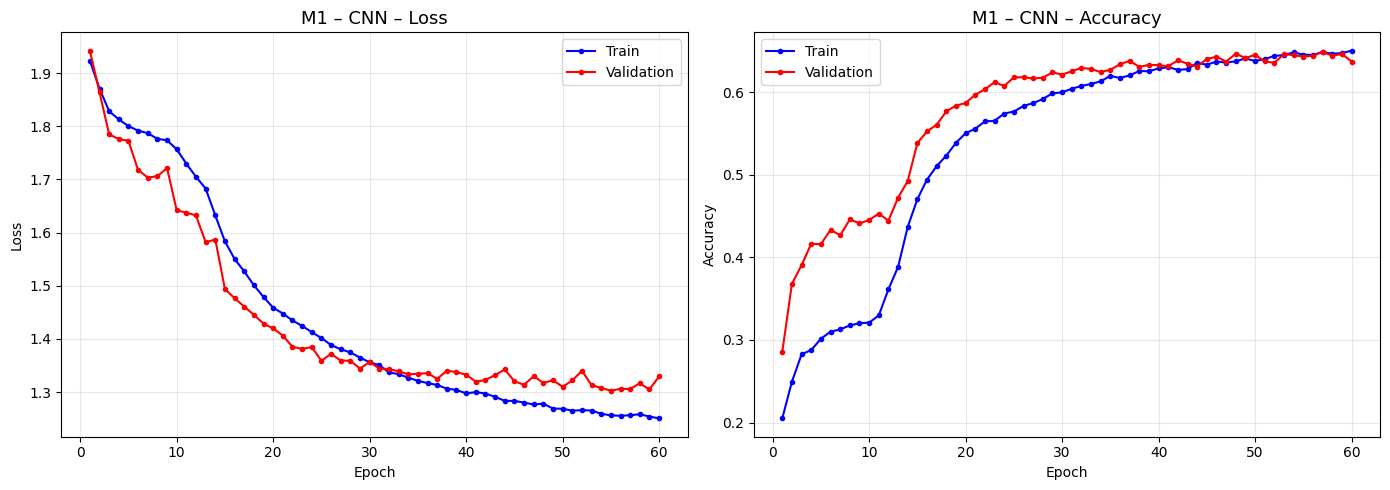

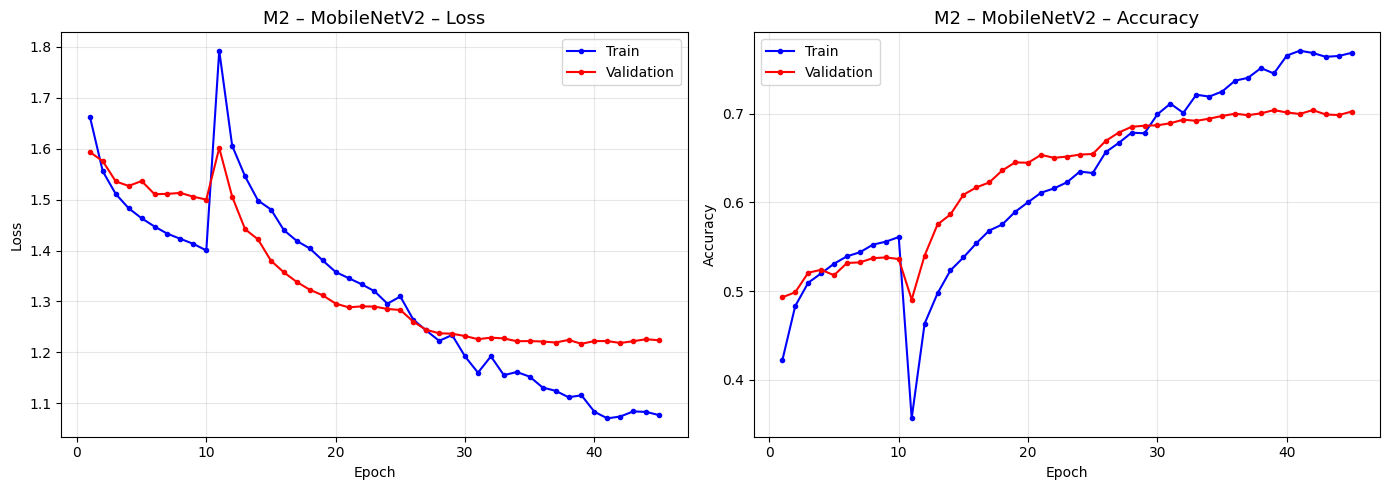

In [9]:
def plot_history(history, title, save_path=None):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    epochs = range(1, len(history['train_loss']) + 1)

    ax1.plot(epochs, history['train_loss'], 'b-o', markersize=3, label='Train')
    ax1.plot(epochs, history['val_loss'],   'r-o', markersize=3, label='Validation')
    ax1.set_title(f'{title} – Loss', fontsize=13)
    ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss'); ax1.legend(); ax1.grid(alpha=0.3)

    ax2.plot(epochs, history['train_acc'], 'b-o', markersize=3, label='Train')
    ax2.plot(epochs, history['val_acc'],   'r-o', markersize=3, label='Validation')
    ax2.set_title(f'{title} – Accuracy', fontsize=13)
    ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy'); ax2.legend(); ax2.grid(alpha=0.3)

    plt.tight_layout()
    if save_path: plt.savefig(save_path, dpi=150)
    plt.show()

plot_history(history_cnn, 'M1 – CNN', 'training_curves_cnn.png')
plot_history(history_mob, 'M2 – MobileNetV2', 'training_curves_mobilenet.png')

## 6. M3  So sanh M1 (Custom CNN) vs M2 (EfficientNet-B0 + CBAM)


In [10]:
@torch.no_grad()
def full_evaluate(model, loader, device, tta=False):
    model.eval()
    all_preds, all_labels = [], []
    t0 = time.time()
    for imgs, labels in loader:
        imgs = imgs.to(device)
        out = model(imgs).softmax(1)
        if tta:
            out = (out + model(torch.flip(imgs, dims=[3])).softmax(1)) / 2
        preds = out.argmax(dim=1).cpu()
        all_preds.extend(preds.numpy())
        all_labels.extend(labels.numpy())
    elapsed = time.time() - t0
    n = len(loader.dataset)
    return np.array(all_preds), np.array(all_labels), n / elapsed

preds_cnn, labels_cnn, fps_cnn = full_evaluate(model_cnn, cnn_test_loader, DEVICE)
preds_mob, labels_mob, fps_mob = full_evaluate(model_mob, mob_test_loader, DEVICE)

acc_cnn = (preds_cnn == labels_cnn).mean()
acc_mob = (preds_mob == labels_mob).mean()

# TTA
preds_cnn_tta, _, _ = full_evaluate(model_cnn, cnn_test_loader, DEVICE, tta=True)
preds_mob_tta, _, _ = full_evaluate(model_mob, mob_test_loader, DEVICE, tta=True)
print(f'CNN  acc: {acc_cnn*100:.2f}% -> TTA {(preds_cnn_tta == labels_cnn).mean()*100:.2f}%')
print(f'M2   acc: {acc_mob*100:.2f}% -> TTA {(preds_mob_tta == labels_mob).mean()*100:.2f}%')


f1_cnn  = f1_score(labels_cnn, preds_cnn, average='macro')
f1_mob  = f1_score(labels_mob, preds_mob, average='macro')
p_cnn   = sum(p.numel() for p in model_cnn.parameters())
p_mob   = sum(p.numel() for p in model_mob.parameters())

print('='*60)
print(f'{"Metric":<20} {"M1 (CNN)":>15} {"M2 (MobileNetV2)":>18}')
print('='*60)
print(f'{"Accuracy":<20} {acc_cnn*100:>14.2f}% {acc_mob*100:>17.2f}%')
print(f'{"Macro F1":<20} {f1_cnn:>15.4f} {f1_mob:>18.4f}')
print(f'{"Parameters":<20} {p_cnn:>15,} {p_mob:>18,}')
print(f'{"FPS (GPU batch)":<20} {fps_cnn:>14.1f} {fps_mob:>17.1f}')
print('='*60)

CNN  acc: 64.85% -> TTA 65.51%
M2   acc: 70.40% -> TTA 70.20%
Metric                      M1 (CNN)   M2 (MobileNetV2)
Accuracy                      64.85%             70.40%
Macro F1                      0.6227             0.6893
Parameters                 1,321,191          4,542,693
FPS (GPU batch)               960.6             557.1


In [11]:
# === Ensemble M1 (CNN) + M2 (EfficientNet-B0+CBAM) ===
@torch.no_grad()
def get_probs(model, loader, device):
    model.eval()
    all_probs = []
    for imgs, _ in loader:
        imgs = imgs.to(device)
        probs = model(imgs).softmax(1).cpu()
        all_probs.append(probs)
    return torch.cat(all_probs).numpy()

probs_cnn = get_probs(model_cnn, cnn_test_loader, DEVICE)
probs_mob = get_probs(model_mob, mob_test_loader, DEVICE)

# labels_cnn == labels_mob (cung TEST_DIR, cung thu tu vi shuffle=False)
print('=== Ensemble (trung binh co trong so) ===')
best_acc, best_w = 0.0, None
for w_mob in [0.5, 0.6, 0.7, 0.8, 0.9]:
    w_cnn = 1 - w_mob
    probs_ens = w_cnn * probs_cnn + w_mob * probs_mob
    preds_ens = probs_ens.argmax(1)
    acc_ens = (preds_ens == labels_mob).mean()
    print(f'  w_cnn={w_cnn:.1f}, w_mob={w_mob:.1f} -> acc = {acc_ens*100:.2f}%')
    if acc_ens > best_acc:
        best_acc, best_w = acc_ens, w_mob

print(f'\nTot nhat: w_mob={best_w:.1f} -> acc = {best_acc*100:.2f}%')
print(f'So sanh: M1 solo = {(preds_cnn == labels_cnn).mean()*100:.2f}% | '
      f'M2 solo = {(preds_mob == labels_mob).mean()*100:.2f}% | '
      f'Ensemble = {best_acc*100:.2f}%')

probs_ens_best = (1 - best_w) * probs_cnn + best_w * probs_mob
preds_ens_best = probs_ens_best.argmax(1)
f1_ens = f1_score(labels_mob, preds_ens_best, average='macro')
print(f'Macro F1 (ensemble): {f1_ens:.4f}')

=== Ensemble (trung binh co trong so) ===
  w_cnn=0.5, w_mob=0.5 -> acc = 70.62%
  w_cnn=0.4, w_mob=0.6 -> acc = 70.70%
  w_cnn=0.3, w_mob=0.7 -> acc = 70.72%
  w_cnn=0.2, w_mob=0.8 -> acc = 70.77%
  w_cnn=0.1, w_mob=0.9 -> acc = 70.60%

Tot nhat: w_mob=0.8 -> acc = 70.77%
So sanh: M1 solo = 64.85% | M2 solo = 70.40% | Ensemble = 70.77%
Macro F1 (ensemble): 0.6938


## 7. M4 – Confusion Matrix & Phân tích lỗi

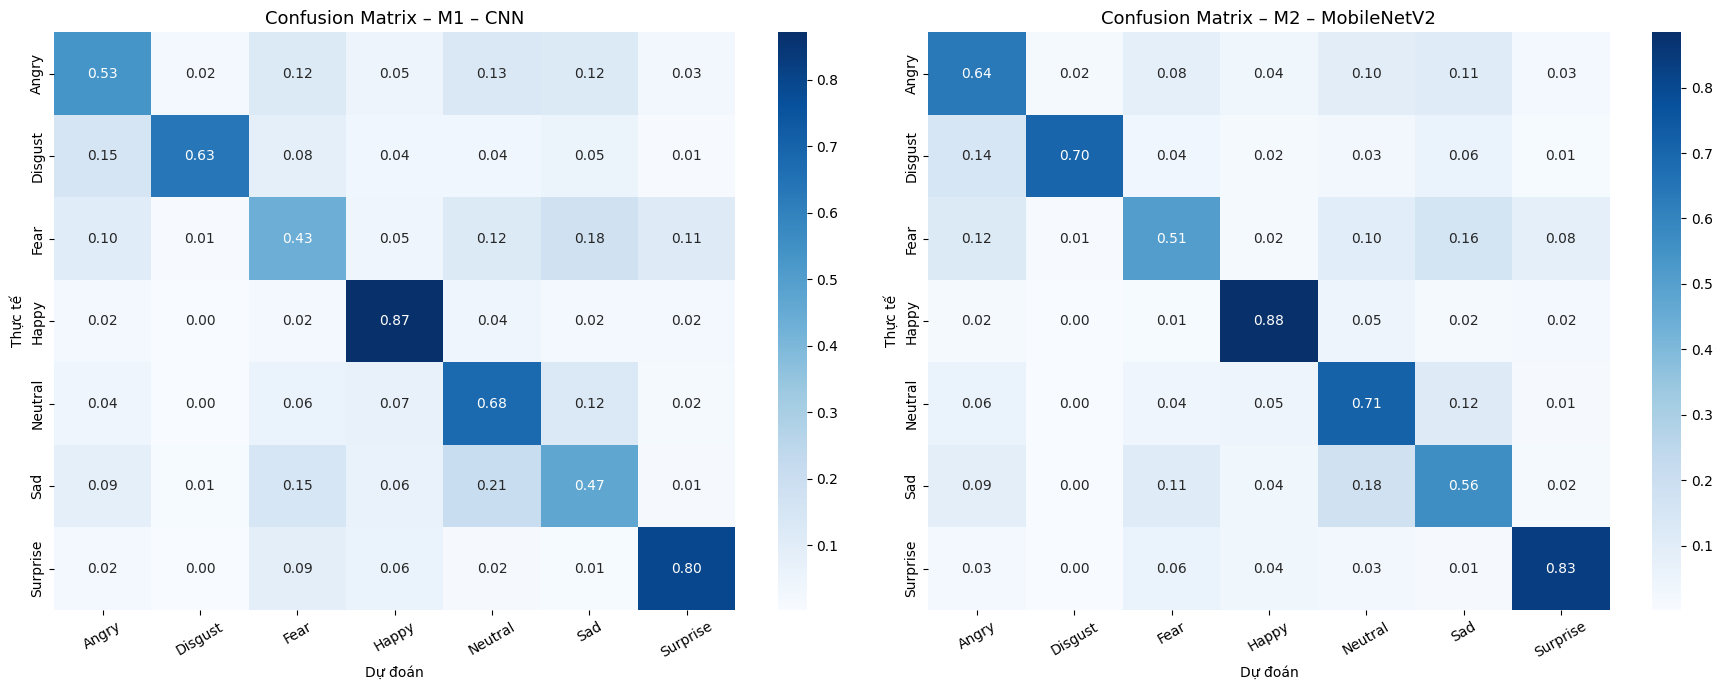

=== Classification Report – MobileNetV2 ===
              precision    recall  f1-score   support

       Angry       0.61      0.64      0.63       958
     Disgust       0.70      0.70      0.70       111
        Fear       0.61      0.51      0.55      1024
       Happy       0.89      0.88      0.89      1774
     Neutral       0.63      0.71      0.67      1233
         Sad       0.60      0.56      0.58      1247
    Surprise       0.79      0.83      0.81       831

    accuracy                           0.70      7178
   macro avg       0.69      0.69      0.69      7178
weighted avg       0.70      0.70      0.70      7178



In [12]:
# ── Confusion Matrix ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, preds, labels, title in [
    (axes[0], preds_cnn, labels_cnn, 'M1 – CNN'),
    (axes[1], preds_mob, labels_mob, 'M2 – MobileNetV2'),
]:
    cm = confusion_matrix(labels, preds)
    # Normalize theo hàng (true label)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_title(f'Confusion Matrix – {title}', fontsize=13)
    ax.set_xlabel('Dự đoán'); ax.set_ylabel('Thực tế')
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

# ── Classification report ────────────────────────────────────────────────
print('=== Classification Report – MobileNetV2 ===')
print(classification_report(labels_mob, preds_mob, target_names=CLASS_NAMES))

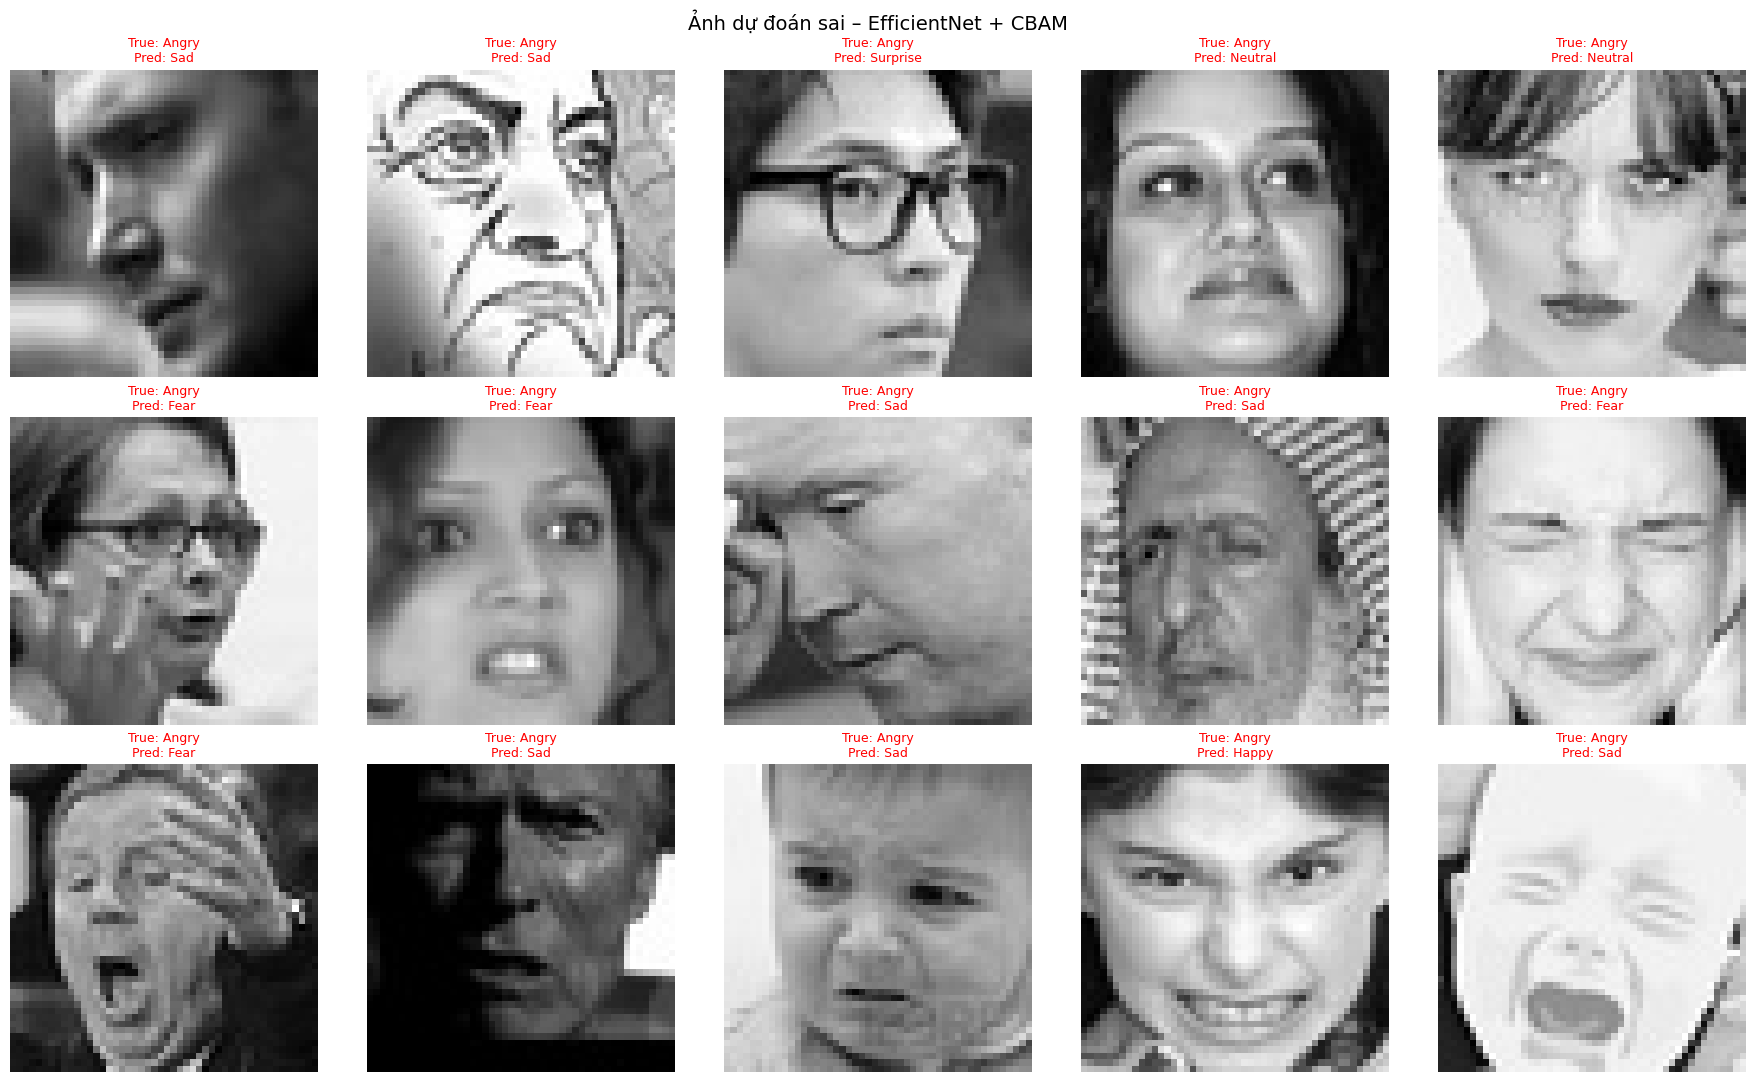

Tổng số ảnh dự đoán sai: 2125/7178 (29.6%)


In [13]:
# ── Phân tích 10 ảnh dự đoán sai (EfficientNet + CBAM) ──────────────────────────
from torchvision.datasets import ImageFolder

test_ds_raw = ImageFolder(TEST_DIR, transform=MOB_TEST_TRANSFORM)
wrong_idxs  = [i for i, (p, l) in enumerate(zip(preds_mob, labels_mob)) if p != l]
sample_idxs = wrong_idxs[:15]   # lấy 15 ảnh sai đầu tiên

fig, axes = plt.subplots(3, 5, figsize=(18, 11))
for ax, idx in zip(axes.flatten(), sample_idxs):
    img_path = test_ds_raw.samples[idx][0]
    from PIL import Image
    img = np.array(Image.open(img_path).convert('L'))
    ax.imshow(img, cmap='gray')
    true_lbl = CLASS_NAMES[labels_mob[idx]]
    pred_lbl = CLASS_NAMES[preds_mob[idx]]
    ax.set_title(f'True: {true_lbl}\nPred: {pred_lbl}', fontsize=9,
                 color='red' if true_lbl != pred_lbl else 'green')
    ax.axis('off')

plt.suptitle('Ảnh dự đoán sai – EfficientNet + CBAM', fontsize=14)
plt.tight_layout()
plt.savefig('wrong_predictions.png', dpi=150)
plt.show()
print(f'Tổng số ảnh dự đoán sai: {len(wrong_idxs)}/{len(labels_mob)} ({len(wrong_idxs)/len(labels_mob)*100:.1f}%)')

## 8. Export – Download weights về máy local

Sau khi notebook chạy xong, download 2 file sau về thư mục `weights/` trên máy:
- `model_cnn.pt`
- `model_mobilenet.pt`

*(Trong Kaggle: click icon thư mục bên phải → Output → Download)*


In [14]:
import os
print('=== Files output ===')
for f in ['model_cnn.pt', 'model_mobilenet.pt',
          'class_distribution.png', 'confusion_matrix.png',
          'training_curves_cnn.png', 'training_curves_mobilenet.png',
          'wrong_predictions.png']:
    size = os.path.getsize(f) / 1e6 if os.path.exists(f) else -1
    status = f'{size:.2f} MB' if size >= 0 else 'NOT FOUND'
    print(f'  {f:<40} {status}')

=== Files output ===
  model_cnn.pt                             5.30 MB
  model_mobilenet.pt                       18.48 MB
  class_distribution.png                   0.07 MB
  confusion_matrix.png                     0.16 MB
  training_curves_cnn.png                  0.09 MB
  training_curves_mobilenet.png            0.10 MB
  wrong_predictions.png                    0.15 MB
